In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


In [2]:
df=pd.read_csv("1.04. Real-life example.csv")
df.head(5)

,Brand,Price,Body,Mileage,EngineV,Engine Type,Registration,Year,Model
0,BMW,4200.0,sedan,277,2.0,Petrol,yes,1991,320
1,Mercedes-Benz,7900.0,van,427,2.9,Diesel,yes,1999,Sprinter 212
2,Mercedes-Benz,13300.0,sedan,358,5.0,Gas,yes,2003,S 500
3,Audi,23000.0,crossover,240,4.2,Petrol,yes,2007,Q7
4,Toyota,18300.0,crossover,120,2.0,Petrol,yes,2011,Rav 4


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4345 entries, 0 to 4344
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Brand         4345 non-null   object 
 1   Price         4173 non-null   float64
 2   Body          4345 non-null   object 
 3   Mileage       4345 non-null   int64  
 4   EngineV       4195 non-null   float64
 5   Engine Type   4345 non-null   object 
 6   Registration  4345 non-null   object 
 7   Year          4345 non-null   int64  
 8   Model         4345 non-null   object 
dtypes: float64(2), int64(2), object(5)
memory usage: 305.6+ KB


In [4]:
df.shape

(4345, 9)

In [5]:
df.isnull().sum()

Brand             0
Price           172
Body              0
Mileage           0
EngineV         150
Engine Type       0
Registration      0
Year              0
Model             0
dtype: int64

In [6]:
df['Price'].fillna(df['Price'].mean(),inplace=True)
df['EngineV'].fillna(df['EngineV'].mean(),inplace=True)

C:\Users\User\AppData\Local\Temp\ipykernel_5044\2375041504.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Price'].fillna(df['Price'].mean(),inplace=True)
C:\Users\User\AppData\Local\Temp\ipykernel_5044\2375041504.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For exam

In [7]:
df.describe()

,Price,Mileage,EngineV,Year
count,4345.000000,4345.000000,4345.000000,4345.000000
mean,19418.746935,161.237284,2.790734,2006.550058
std,25072.625077,105.705797,4.978196,6.719097
min,600.000000,0.000000,0.600000,1969.000000
25%,7100.000000,86.000000,1.900000,2003.000000
50%,11900.000000,155.000000,2.200000,2008.000000
75%,20900.000000,230.000000,3.000000,2012.000000
max,300000.000000,980.000000,99.990000,2016.000000


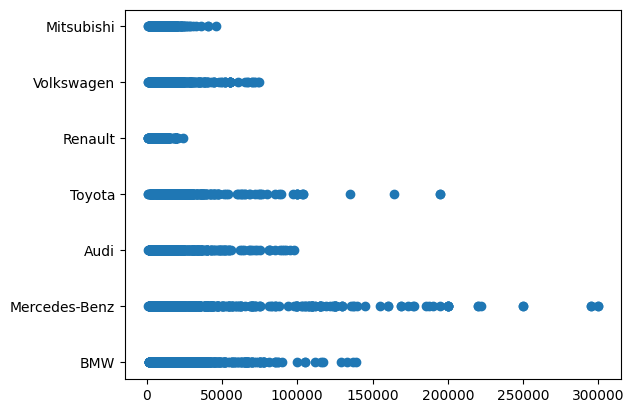

In [8]:
plt.scatter(df['Price'],df['Brand'])

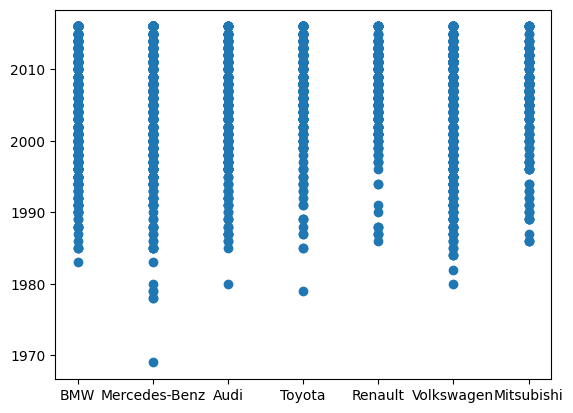

In [9]:
plt.scatter(df['Brand'],df['Year'])

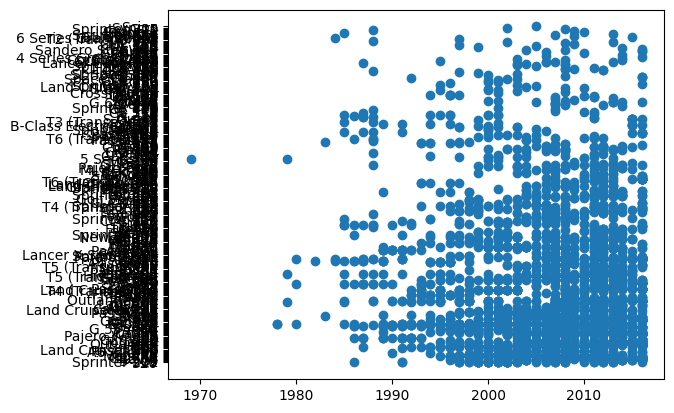

In [10]:
plt.scatter(df['Year'],df['Model'])

<Axes: xlabel='Price', ylabel='Density'>

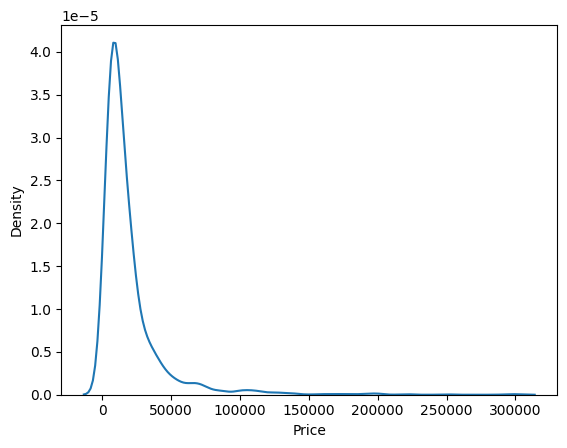

In [11]:
sns.kdeplot(df['Price'])

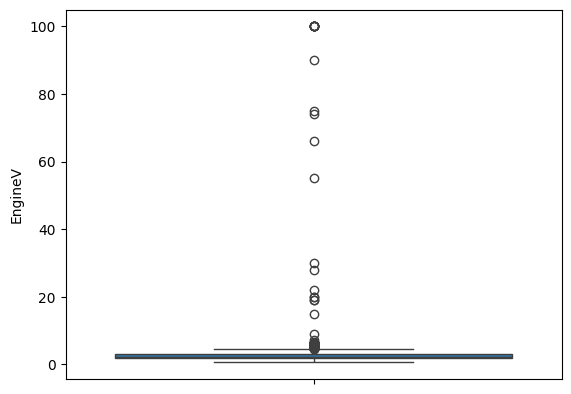

In [13]:
num_col=['EngineV']
sns.boxplot(data=df['EngineV'])

df=df[df['EngineV']<=10]

<Axes: ylabel='EngineV'>

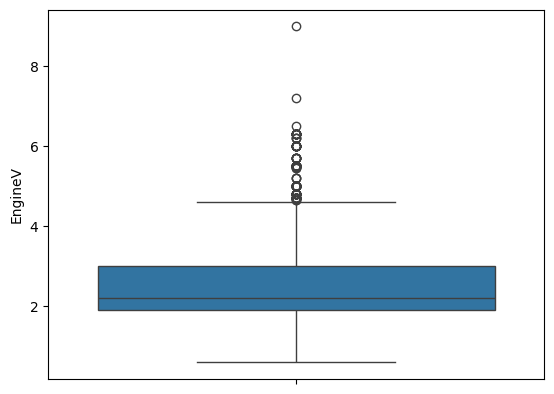

In [14]:
sns.boxplot(data=df['EngineV'])

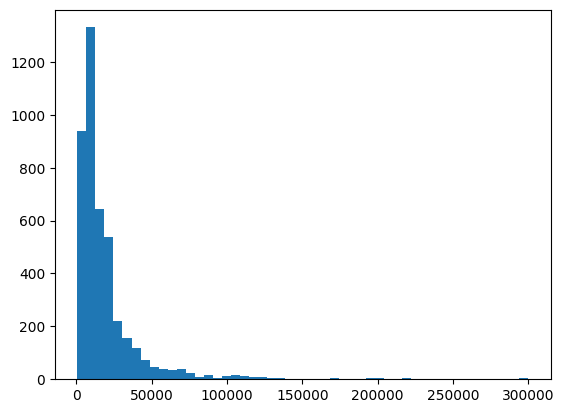

In [16]:
plt.hist(df['Price'],bins=50)
plt.show()

(array([  2.,   0.,   2.,   0.,   2.,   7.,  12.,  21.,  18.,  34.,  55.,
         76.,  76.,  64.,  87.,  94.,  95., 110., 120., 229., 229., 298.,
        242., 268., 268., 213., 162., 357., 173., 151., 108., 138., 106.,
        102.,  67.,  65.,  40.,  48.,  49.,  23.,  15.,  34.,  21.,  13.,
          4.,   6.,  11.,   3.,   2.,   4.]),
 array([ 6.39692966,  6.52122182,  6.64551398,  6.76980614,  6.8940983 ,
         7.01839047,  7.14268263,  7.26697479,  7.39126695,  7.51555911,
         7.63985127,  7.76414344,  7.8884356 ,  8.01272776,  8.13701992,
         8.26131208,  8.38560425,  8.50989641,  8.63418857,  8.75848073,
         8.88277289,  9.00706506,  9.13135722,  9.25564938,  9.37994154,
         9.5042337 ,  9.62852587,  9.75281803,  9.87711019, 10.00140235,
        10.12569451, 10.24998668, 10.37427884, 10.498571  , 10.62286316,
        10.74715532, 10.87144749, 10.99573965, 11.12003181, 11.24432397,
        11.36861613, 11.4929083 , 11.61720046, 11.74149262, 11.86578478,
 

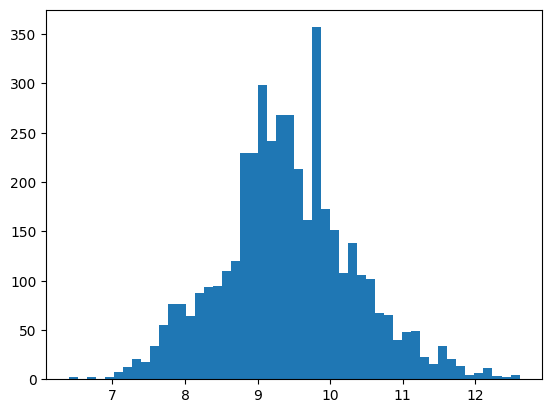

In [17]:
df['Log_price']=np.log(df['Price'])
plt.hist(df['Log_price'],bins=50)

In [19]:
df['Model'].nunique()

311

In [20]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()


In [21]:
cat_col=df.select_dtypes(include='object').columns
for col in cat_col:
    df[col]=le.fit_transform(df[col])
df    

,Brand,Price,Body,Mileage,EngineV,Engine Type,Registration,Year,Model,Log_price
0,1,4200.0,3,277,2.000000,3,1,1991,18,8.342840
1,2,7900.0,5,427,2.900000,0,1,1999,265,8.974618
2,2,13300.0,3,358,5.000000,1,1,2003,237,9.495519
3,0,23000.0,0,240,4.200000,3,1,2007,224,10.043249
4,5,18300.0,0,120,2.000000,3,1,2011,227,9.814656
...,...,...,...,...,...,...,...,...,...,...
4340,2,125000.0,3,9,3.000000,0,1,2014,233,11.736069
4341,1,6500.0,3,1,3.500000,3,1,1999,37,8.779557
4342,1,8000.0,3,194,2.000000,3,1,1985,31,8.987197
4343,5,14200.0,3,31,2.790734,3,1,2014,114,9.560997


<Axes: >

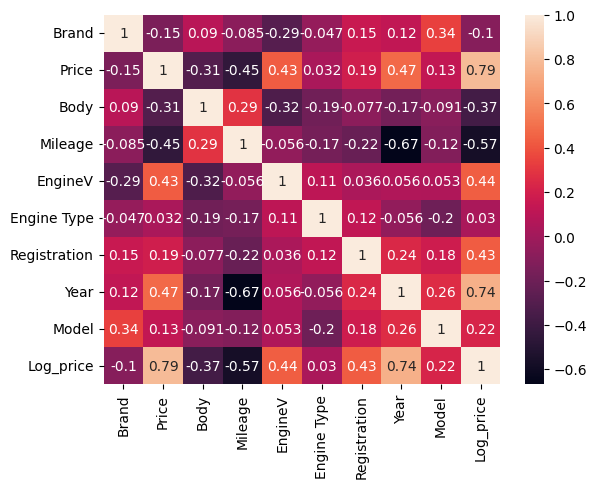

In [22]:
sns.heatmap(df.corr(),annot=True)

In [24]:
X=df.drop(["Log_price"],axis=1)
Y=df['Log_price']

In [25]:
from sklearn.model_selection import train_test_split

In [26]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=42)

In [ ]:
from sklearn.linear_model import LinearRegression
reg=LinearRegression()
reg.fit(X_train,Y_train)


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [70]:
Y_Predict=reg.predict(X_test)
Y_Predict[ :10]

array([11.15590659,  9.43487036,  9.4726092 ,  8.95866348,  9.45627779,
        8.54342731, 10.20144688,  9.5898611 ,  9.75933347, 10.15757635])

In [54]:
compare=pd.DataFrame({
    "Actual":Y_test,
    "Y_Predict":Y_Predict
})

In [32]:
compare.head(4)

,Actual,Y_Predict
2134,11.308358,11.155907
17,9.873994,9.434870
3735,9.648595,9.472609
586,8.922658,8.958663


In [43]:
from sklearn.metrics import r2_score,mean_squared_error

In [35]:
r2_score(Y_test,Y_Predict)*100

87.4163662269113

In [ ]:
from sklearn.linear_model import Ridge
clf=Ridge()
clf.fit(X_train,Y_train)


,alpha,1.0
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


In [56]:
Y_predict=clf.predict(X_test)
Y_predict[ :10]

array([11.15605206,  9.43457756,  9.47270204,  8.95820975,  9.45648969,
        8.54276221, 10.20143125,  9.58954439,  9.75915605, 10.15716202])

In [58]:
compare=pd.DataFrame({
    "Actual":Y_test,
    "Y_Predict":Y_predict
})

In [59]:
compare.head(5)

,Actual,Y_Predict
2134,11.308358,11.156052
17,9.873994,9.434578
3735,9.648595,9.472702
586,8.922658,8.958210
4269,9.674074,9.456490


In [60]:
import numpy as np
from sklearn.linear_model import Lasso

In [61]:
lasso=Lasso(alpha=1.0,random_state=42)
lasso.fit(X_train,Y_train)

,alpha,1.0
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,1000
,tol,0.0001
,warm_start,False
,positive,False
,random_state,42
,selection,'cyclic'


In [62]:
y_pred_lasso=lasso.predict(X_test)

In [63]:
mse=mean_squared_error(Y_test,y_pred_lasso)
rmse=np.sqrt(mse)
r2=r2_score(Y_test,y_pred_lasso)
print(mse)
print(rmse)
print(r2)

0.21176621008451263
0.46018062767190954
0.7322876479322524


In [65]:
coeff_df=pd.DataFrame({
    "Feature":X.columns,
    "Cofficient":lasso.coef_
})

In [66]:
print(coeff_df)

        Feature  Cofficient
0         Brand   -0.000000
1         Price    0.000022
2          Body   -0.000000
3       Mileage   -0.001558
4       EngineV    0.000000
5   Engine Type   -0.000000
6  Registration    0.000000
7          Year    0.020093
8         Model    0.000610


In [67]:
reg=LinearRegression()
reg.fit(X_train,Y_train)

clf=Ridge()
clf.fit(X_train,Y_train)

lasso=Lasso(alpha=1.0,random_state=42)
lasso.fit(X_train,Y_train)

,alpha,1.0
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,1000
,tol,0.0001
,warm_start,False
,positive,False
,random_state,42
,selection,'cyclic'


In [71]:
# Lr-metrics
mse=mean_squared_error(Y_test,Y_Predict)
rmse=np.sqrt(mse)
r2=r2_score(Y_test,Y_Predict)
print(mse)
print(rmse)
print(r2)

0.09953924100387113
0.31549840095295434
0.8741636622691129


In [72]:

# Ridge-metrics
mse=mean_squared_error(Y_test,Y_predict)
rmse=np.sqrt(mse)
r2=r2_score(Y_test,Y_predict)
print(mse)
print(rmse)
print(r2)

0.09951950356016327
0.3154671196181359
0.8741886141133034


In [73]:
# Lasso-metrics
mse=mean_squared_error(Y_test,y_pred_lasso)
rmse=np.sqrt(mse)
r2=r2_score(Y_test,y_pred_lasso)
print(mse)
print(rmse)
print(r2)

0.21176621008451263
0.46018062767190954
0.7322876479322524


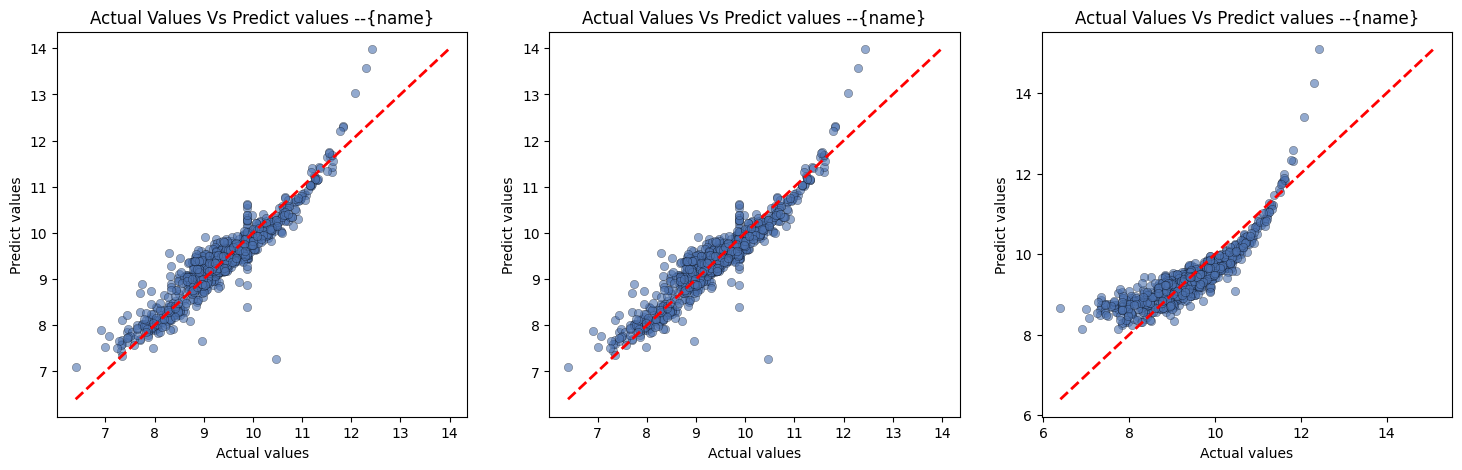

In [78]:
fig,axes=plt.subplots(1,3,figsize=(18,5))

models_preds={
    'LinearRegression':Y_Predict,
    'Ridge':Y_predict,
    'Lasso':y_pred_lasso
}
for ax,(name,preds) in zip(axes,models_preds.items()):
    ax.scatter(Y_test,preds,alpha=0.6,color='#4C72B0',edgecolor='k',linewidth=0.3)
    min_val=min(Y_test.min(),preds.min())
    max_val=max(Y_test.max(),preds.max())
    ax.plot([min_val,max_val],[min_val,max_val],color='red',linestyle='--',linewidth=2)
    ax.set_xlabel('Actual values')
    ax.set_ylabel('Predict values')
    ax.set_title('Actual Values Vs Predict values --{name}')
